# Experiment 09: CART Decision Tree Classification

## Aim
To implement the CART (Classification and Regression Trees) algorithm for classification and evaluate its performance.

## Dataset and source
- **Dataset:** Breast Cancer Wisconsin Diagnostic
- **Source:** Built into scikit-learn (`load_breast_cancer`)
- **Size:** 569 samples and 30 numeric features
- **Classes:** malignant and benign
- **Kaggle download:** Not required

## Theory
CART stands for **Classification and Regression Trees**. It can be used for both classification and regression tasks. CART builds a binary tree: each internal node splits data into two child nodes.

For classification, CART commonly uses Gini impurity:

\[
Gini(S)=1-\sum_{i=1}^{k}p_i^2
\]

A split is selected to reduce the weighted impurity of the child nodes. In this experiment, `criterion="gini"` and `splitter="best"` are used. `max_depth=4` limits the tree depth to help reduce overfitting.

For regression, CART typically selects splits that reduce squared error/variance, and leaf nodes predict a numeric value.

## Algorithm
1. Load the Breast Cancer Wisconsin dataset.
2. Separate features and target labels.
3. Split data into training and testing sets.
4. Create a CART-style Decision Tree classifier using Gini impurity.
5. Train the classifier.
6. Predict labels for the test set.
7. Evaluate accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.
8. Visualize the tree, confusion matrix, ROC curve, and feature importances.

## Implementation note
`sklearn.tree.DecisionTreeClassifier` implements an optimized CART-style decision tree. For this classification task, it uses binary splits and the Gini criterion.


## Program


Dataset: Breast Cancer Wisconsin Diagnostic
Dataset source: scikit-learn built-in dataset
Number of rows: 569
Number of features: 30
Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}

Class distribution:
target
malignant    212
benign       357
Name: count, dtype: int64

Algorithm: CART Decision Tree
Criterion: Gini impurity
Split strategy: Best binary split
Maximum depth: 4
Number of leaves: 11
Training samples: 455
Testing samples: 114
Accuracy: 0.9386 (93.86%)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Confusion Matrix:
[[39  3]
 [ 4 68]]
ROC-AUC: 0.9342


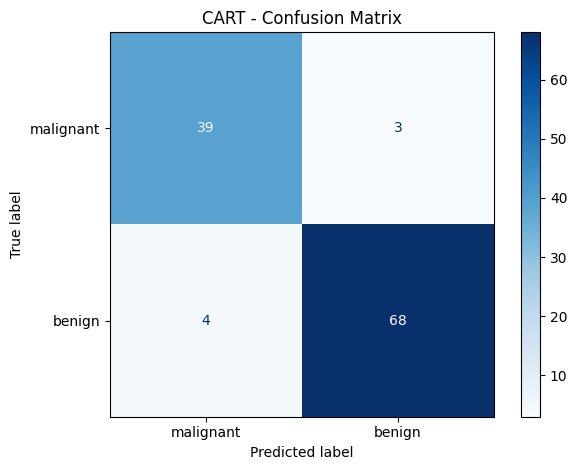

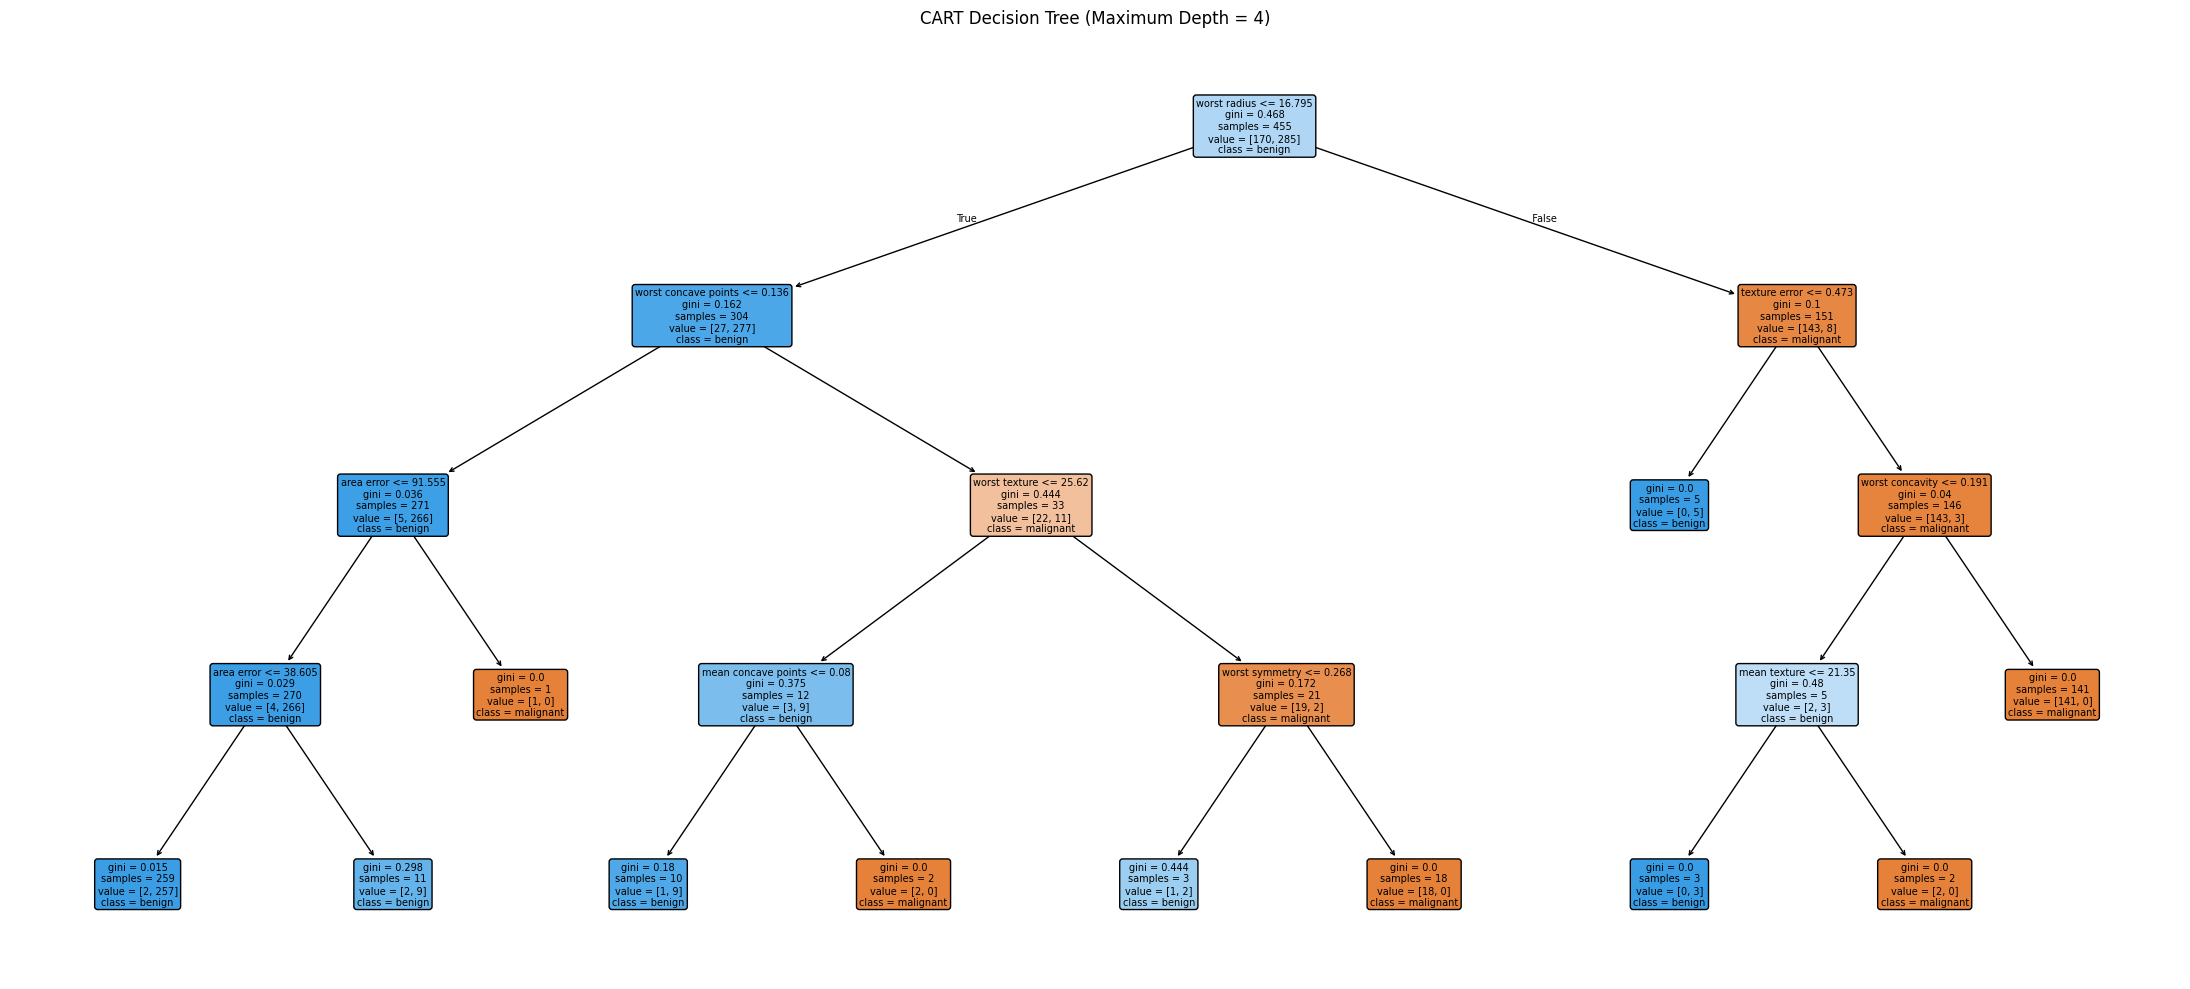

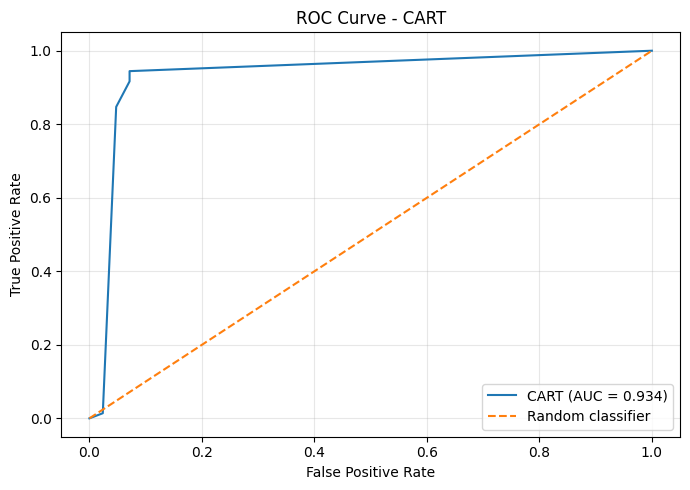


Top 10 Feature Importances:
worst radius            0.7335
worst concave points    0.1220
texture error           0.0458
worst texture           0.0323
worst concavity         0.0172
mean concave points     0.0133
area error              0.0127
mean texture            0.0118
worst symmetry          0.0113
mean area               0.0000
dtype: float64


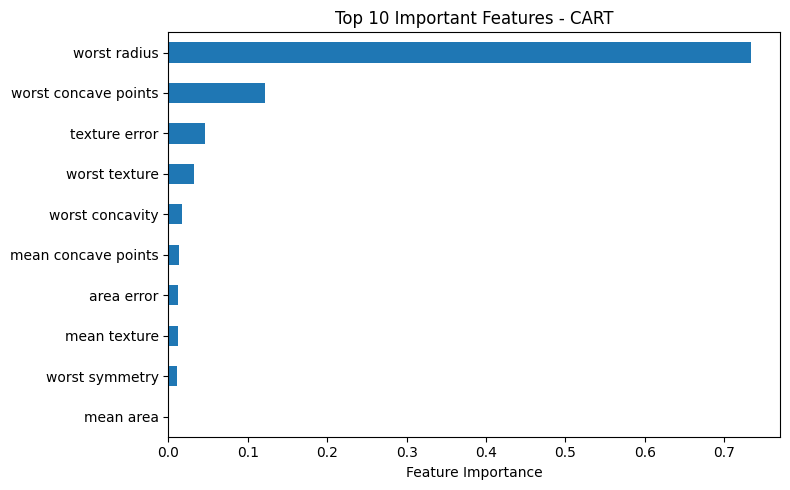


Sample Prediction:
Predicted class: malignant
Actual class:    malignant


In [1]:
"""
Experiment 09: CART Decision Tree Classification
Dataset: Breast Cancer Wisconsin Diagnostic (built into scikit-learn)

CART = Classification and Regression Trees.
For classification, this experiment uses Gini impurity and binary splits.
scikit-learn's DecisionTreeClassifier implements an optimized CART-style tree.
"""

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# 1. Load the dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
target_names = data.target_names

print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Dataset source: scikit-learn built-in dataset")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Class labels:", dict(enumerate(target_names)))

print("\nClass distribution:")
print(
    y.value_counts()
     .sort_index()
     .rename(index=dict(enumerate(target_names)))
)

# 2. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Create the CART classifier.
# CART uses binary splits; Gini impurity is the default classification criterion.
model = DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    max_depth=4,
    random_state=42
)

# 4. Train the model
model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 6. Evaluate model
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("\nAlgorithm: CART Decision Tree")
print("Criterion: Gini impurity")
print("Split strategy: Best binary split")
print("Maximum depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_names,
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print(f"ROC-AUC: {auc:.4f}")

# 7. Confusion matrix visualization
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=target_names,
    cmap="Blues",
    values_format="d"
)
plt.title("CART - Confusion Matrix")
plt.tight_layout()
plt.show()

# 8. Plot the CART tree
plt.figure(figsize=(22, 10))
plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=list(target_names),
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("CART Decision Tree (Maximum Depth = 4)")
plt.tight_layout()
plt.show()

# 9. ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"CART (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - CART")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 10 Feature Importances:")
print(importance.head(10).round(4))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)
plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features - CART")
plt.tight_layout()
plt.show()

# 11. Predict a single test sample
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]

print("\nSample Prediction:")
print("Predicted class:", target_names[prediction])
print("Actual class:   ", target_names[y_test.iloc[0]])


## Expected output
The program prints the dataset size, class distribution, train/test sizes, tree depth, number of leaves, classification metrics, confusion matrix, ROC-AUC, and top feature importances. It displays four plots: confusion matrix, tree diagram, ROC curve, and feature importance chart.

The exact metrics are generated when the code runs. Since the split uses `random_state=42`, results are reproducible with a consistent scikit-learn version.

## Result
The CART-style Decision Tree classifier was trained and tested on the Breast Cancer Wisconsin dataset. Its classification performance was measured using evaluation metrics and visualizations.

## Viva-voce questions and answers

**1. What is CART?**  
CART stands for Classification and Regression Trees, a tree-based method used for classification and regression.

**2. What is the main feature of CART?**  
It builds a binary tree, splitting each internal node into two child nodes.

**3. Which impurity measure does CART use for classification in this experiment?**  
Gini impurity.

**4. What is the Gini impurity formula?**  
\(Gini=1-\sum_i p_i^2\), where \(p_i\) is the proportion of class \(i\) at a node.

**5. How does CART differ from C4.5?**  
CART uses binary splits and commonly uses Gini impurity for classification. C4.5 uses gain ratio and may produce multiway splits for categorical attributes.

**6. Can CART perform regression?**  
Yes. Regression trees predict continuous numeric values.

**7. What does `max_depth` do?**  
It limits the tree's depth and can reduce overfitting.

**8. What is a leaf node?**  
A terminal node that produces the final class or numeric prediction.

**9. Does CART require feature scaling?**  
Usually no, because its splits are based on feature thresholds.

**10. What is pruning?**  
Pruning reduces tree complexity by removing branches that are unlikely to generalize well.

**11. Why is a test set needed?**  
It estimates model performance on data that was not used to train the tree.

**12. What does ROC-AUC measure?**  
It measures how well the model ranks positive samples above negative samples across classification thresholds.
